# T16b: which reliability gates over-decline on short coverage?

Regenerates every figure and table in `README.md` from `data/`:
- `data/stars.csv.gz`, `data/candidates.csv.gz` (from `make_data.py`, which collects the instrumented
  scorecard runs and the pb_scan noise candidate dumps);
- `data/examples.{json,npz}` (from `examples.py`).

Datasets: synthetic n=200 seed 0 under `--coverage full / consecutive-2 / gapped-2 / single` (coverage seed 0;
same stars each time), dev_medium with assigned coverage, pb_scan noise (40 light curves per 1/2/13 sectors).
Held-out validation: synthetic seed 1 (single, gapped-2) and pb_scan noise with seed offset 1500.

In [1]:
import sys, warnings
warnings.simplefilter("ignore")
sys.path.insert(0, ".")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import gate_lib as gl, figs, rules
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
stars, cands = gl.load_data()
stars.groupby("dataset").size()

dataset
consecutive-2     200
dev_medium       1000
full              200
gapped-2          200
noise-13s          40
noise-1s           40
noise-2s           40
s1-gapped-2       200
s1-single         200
single            200
v-noise-13s        40
v-noise-1s         40
v-noise-2s         40
dtype: int64

## 0. Instrumentation is bit-identical (final periods and outcomes)

In [2]:
print(open("data/bit_identity_compare_runs.txt").read())

200 stars in common
final_period differs: 0 stars
final_outcome differs: 0 stars
  acf_fft                top1 differs:   0   n_candidates differs:   0
  acf_fft_highpass       top1 differs:   0   n_candidates differs:   0
  acf_fft_short          top1 differs:   0   n_candidates differs:   0
  lombscargle            top1 differs:   0   n_candidates differs:   0
  lombscargle_short      top1 differs:   0   n_candidates differs:   0
  pairwise_histogram     top1 differs:   0   n_candidates differs:   0
  wavelet                top1 differs:   0   n_candidates differs:   3
DIFFERENT

50 stars in common
final_period differs: 0 stars
final_outcome differs: 0 stars
  acf_fft                top1 differs:   0   n_candidates differs:   0
  acf_fft_highpass       top1 differs:   0   n_candidates differs:   0
  acf_fft_short          top1 differs:   0   n_candidates differs:   0
  lombscargle            top1 differs:   0   n_candidates differs:   0
  lombscargle_short      top1 differs:   0   n_

## 1. Outcomes per dataset
`noise-*` rows: pb_scan noise light curves (`noise` = the pipeline answered, i.e. a false positive).

In [3]:
cls = np.where(stars.final_outcome.eq("none"), "none", gl.cand_class(stars.final_outcome))
overview = pd.crosstab(stars.dataset, cls)
overview["n"] = overview.sum(axis=1)
overview

col_0,alias,noise,none,success,wrong,n
dataset,,,,,,
consecutive-2,3,0,109,84,4,200
dev_medium,9,0,789,148,54,1000
full,0,0,54,146,0,200
gapped-2,1,0,128,69,2,200
noise-13s,0,0,40,0,0,40
noise-1s,0,0,40,0,0,40
noise-2s,0,0,40,0,0,40
s1-gapped-2,0,0,128,72,0,200
s1-single,0,0,134,64,2,200


## 2. Declined stars that had a success candidate in the fitted pool, under three definitions
- **loose**: the candidate's fitted P scores success (`correct` or `diffrot`), which is what the brief asked for.
  For differential rotators the active-band range can span several times P_eq, so this over-counts.
- **strict**: fitted P within REL_TOL of P_eq (`correct`).
- **matched** (synthetic coverage runs only): within 3% of the same star's full-year final period, for stars
  the full-year run measured, i.e. "the short-coverage pool contains the answer the full-year run gives".

In [4]:
rows = {}
for d in ("loose", "strict", "matched"):
    b = figs.rescue_candidates(stars, cands, d)
    rows[d] = b.groupby("dataset").size()
dec = stars[stars.final_outcome.eq("none")].groupby("dataset").size().rename("declined")
rescue_counts = pd.concat([dec, pd.DataFrame(rows)], axis=1).fillna(0).astype(int)
rescue_counts = rescue_counts.loc[[d for d in figs.COV_ORDER + ["dev_medium", "s1-single", "s1-gapped-2"] if d in rescue_counts.index]]
rescue_counts.to_csv("data/table_rescue_counts.csv")
rescue_counts

,declined,loose,strict,matched
dataset,,,,
full,54,26,20,0
consecutive-2,109,50,35,10
gapped-2,128,47,27,10
single,132,46,26,6
dev_medium,789,370,312,0
s1-single,134,57,38,0
s1-gapped-2,128,48,32,0


How wide are the active-latitude bands of the stars whose only "success" candidates are loose?
(band width = (P_hi - P_lo) / P_eq; any period in that range scores success)

In [5]:
lo = figs.rescue_candidates(stars, cands, "loose")
st = figs.rescue_candidates(stars, cands, "strict")
only_loose = lo[~lo.set_index(["dataset", "star_id"]).index.isin(st.set_index(["dataset", "star_id"]).index)]
w = only_loose.merge(stars[["dataset", "star_id", "period_lo", "period_hi"]], on=["dataset", "star_id"])
w["band_width"] = (w.period_hi - w.period_lo) / w.true_period
w.groupby("dataset").band_width.describe(percentiles=[.25, .5, .75]).round(2)

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
consecutive-2,15.0,0.71,0.94,0.05,0.19,0.49,0.72,3.72
dev_medium,58.0,0.45,0.84,0.03,0.10,0.19,0.36,4.47
full,6.0,1.17,1.29,0.24,0.47,0.86,0.97,3.72
gapped-2,20.0,0.70,0.93,0.03,0.19,0.44,0.81,4.23
s1-gapped-2,16.0,0.68,1.12,0.09,0.21,0.30,0.39,4.15
s1-single,19.0,0.48,0.69,0.02,0.16,0.22,0.49,3.07
single,20.0,0.79,1.20,0.04,0.10,0.25,0.94,4.23


## 3. Gate attribution: coverage x period bin x gate

For each declined star, take its best (lowest-redchi) success candidate and list the gates it failed.
`any` = candidates failing that gate (with or without others); `sole` = failing only that gate (relaxing that gate alone
would make the candidate pass, though it may still lose to another passing candidate).

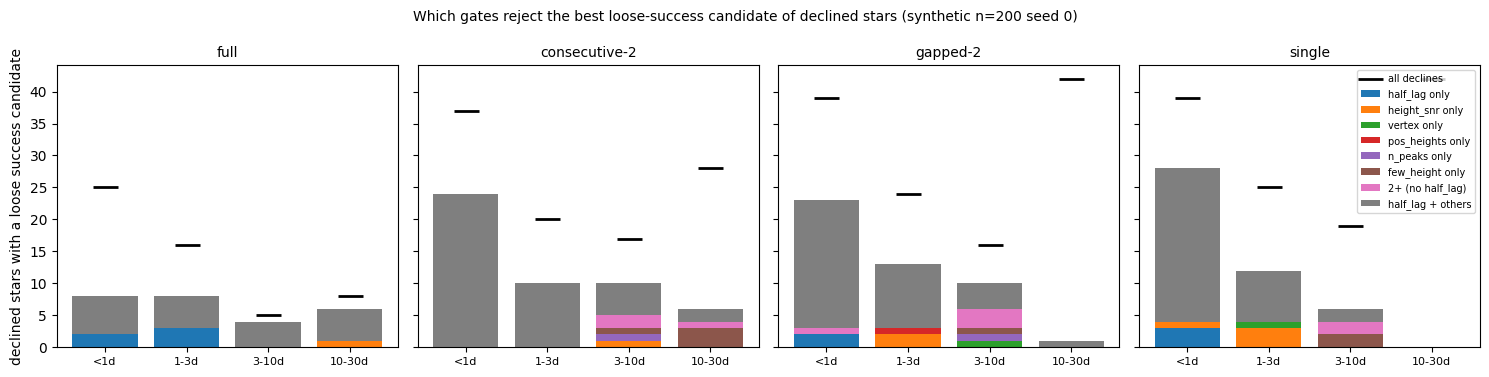

In [6]:
fig = figs.fig_decline_attribution(stars, cands, "loose", out="figures/fig_attribution_loose.png")

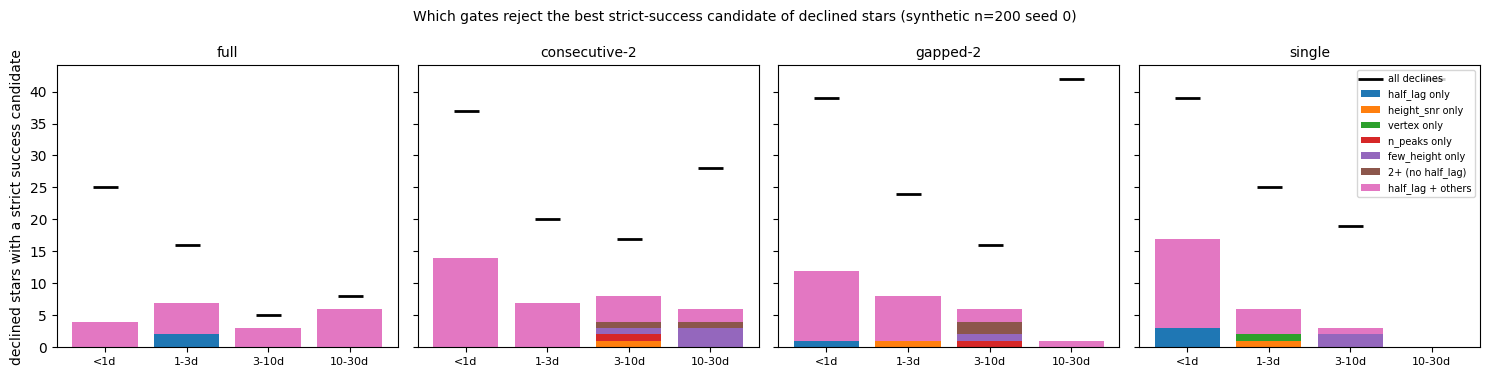

In [7]:
fig = figs.fig_decline_attribution(stars, cands, "strict", out="figures/fig_attribution_strict.png")

In [8]:
tabs = {}
for d in ("loose", "strict", "matched"):
    b = figs.rescue_candidates(stars, cands, d)
    t = figs.gate_table(b[b.dataset.isin(figs.COV_ORDER + ["dev_medium"])], by=("dataset", "period_bin"))
    t.to_csv(f"data/table_gates_{d}_by_bin.csv")
    tabs[d] = t
tabs["loose"]

any                                                      sole                                                  
                         n_stars n_peaks pos_heights height_snr vertex half_lag few_height n_peaks pos_heights height_snr vertex half_lag few_height
dataset       period_bin                                                                                                                            
consecutive-2 1-3d            10       0           5         10      5       10          0       0           0          0      0        0          0
              10-30d           6       0           2          3      2        2          6       0           0          0      0        0          3
              3-10d           10       1           3          8      4        5          4       1           0          1      0        0          1
              <1d             24       0           5         16     14       24          0       0           0          0      0        0          0
dev_medium    1-3d           106       0          70         89     54       91          0       0           0          7      3        4          0
              10-30d          52       2          14         48     23       30         19       0           0          7      1        0          2
              3-10d          108       1          59         99     40       73         19       0           1         12      3        0          1
              <1d             64       0          18         35     41       61          0       0           0          1      1        7          0
              >30d            40       0           7         31     12       16         29       0           0          2      0        0          6
full          1-3d             8       0           0          2      4        8          0       0           0          0      0        3          0
              10-30d           6       0           4          6      5        5          0       0           0          1      0        0          0
              3-10d            4       0           1          4      2        4          0       0           0          0      0        0          0
              <1d              8       0           1          2      5        8          0       0           0          0      0        2          0
gapped-2      1-3d            13       0           6         12      5       10          0       0           1          2      0        0          0
              10-30d           1       0           0          1      1        1          1       0           0          0      0        0          0
              3-10d           10       1           3          7      4        4          7       1           0          0      1        0          1
              <1d             23       0           3         17     10       22          0       0           0          0      0        2          0
single        1-3d            12       0           8         11      5        8          0       0           0          3      1        0          0
              3-10d            6       0           1          4      2        2          2       0           0          0      0        0          2
              <1d             28       0           6         23     13       27          0       0           0          1      0        3          0

In [9]:
tabs["strict"]

any                                                      sole                                                  
                         n_stars n_peaks pos_heights height_snr vertex half_lag few_height n_peaks pos_heights height_snr vertex half_lag few_height
dataset       period_bin                                                                                                                            
consecutive-2 1-3d             7       0           3          6      3        7          0       0           0          0      0        0          0
              10-30d           6       0           2          3      2        2          6       0           0          0      0        0          3
              3-10d            8       1           3          6      3        4          2       1           0          1      0        0          1
              <1d             14       0           4          9      7       14          0       0           0          0      0        0          0
dev_medium    1-3d            89       0          59         71     49       79          0       0           0          3      2        3          0
              10-30d          48       2          16         44     21       32         17       0           0          5      0        0          2
              3-10d           93       1          57         84     40       64         15       0           1          9      2        0          0
              <1d             51       0          13         27     37       49          0       0           0          1      1        4          0
              >30d            31       0           5         27      8       13         22       0           0          2      0        0          3
full          1-3d             7       0           0          2      4        7          0       0           0          0      0        2          0
              10-30d           6       0           4          5      6        6          0       0           0          0      0        0          0
              3-10d            3       0           1          3      1        3          0       0           0          0      0        0          0
              <1d              4       0           1          1      3        4          0       0           0          0      0        0          0
gapped-2      1-3d             8       0           4          8      4        7          0       0           0          1      0        0          0
              10-30d           1       0           0          1      1        1          1       0           0          0      0        0          0
              3-10d            6       1           1          4      2        2          5       1           0          0      0        0          1
              <1d             12       0           0          8      7       12          0       0           0          0      0        1          0
single        1-3d             6       0           3          3      4        4          0       0           0          1      1        0          0
              3-10d            3       0           0          1      0        1          2       0           0          0      0        0          2
              <1d             17       0           4         14      7       17          0       0           0          0      0        3          0

In [10]:
b = figs.rescue_candidates(stars, cands, "strict")
figs.gate_table(b[b.dataset.isin(figs.COV_ORDER + ["dev_medium"])], by=("dataset",))

any                                                      sole                                                  
              n_stars n_peaks pos_heights height_snr vertex half_lag few_height n_peaks pos_heights height_snr vertex half_lag few_height
dataset                                                                                                                                  
consecutive-2      35       1          12         24     15       27          8       1           0          1      0        0          4
dev_medium        312       3         150        253    155      237         54       0           1         20      5        7          5
full               20       0           6         11     14       20          0       0           0          0      0        2          0
gapped-2           27       1           5         21     14       22          6       1           0          1      0        1          1
single             26       0           7         18     11       22          2       0           0          1      1        3          2

### Strict rescue candidates: is their ACF structured at all?
Mean half-lag contrast of the strict rescue candidates. |contrast| < 0.02 is where pb_scan noise combs sit
(90th percentile of noise best candidates: ~0.01-0.02).

In [11]:
st = figs.rescue_candidates(stars, cands, "strict")
st["structured"] = pd.cut(st.half_lag_contrast, [-np.inf, 0.02, 0.1, np.inf],
                          labels=["noise-like (<0.02)", "weak (0.02-0.1)", "structured (>=0.1)"])
pd.crosstab([st.dataset], st.structured).loc[lambda d: d.index.isin(figs.COV_ORDER + ["dev_medium"])]

structured,noise-like (<0.02),weak (0.02-0.1),structured (>=0.1)
dataset,,,
consecutive-2,27,2,6
dev_medium,202,71,39
full,20,0,0
gapped-2,22,1,4
single,22,1,3


In [12]:
cols = ["dataset", "star_id", "true_period", "P_fit", "failed_gates", "mean_height_snr_value",
        "half_lag_consistency_value", "half_lag_contrast", "frac_vertex_in_window_value",
        "frac_positive_heights_value", "few_peaks_height_value", "n_teeth_available"]
st[st.half_lag_contrast >= 0.1].sort_values(["dataset", "true_period"])[cols].round(3)

,dataset,star_id,true_period,P_fit,failed_gates,mean_height_snr_value,half_lag_consistency_value,half_lag_contrast,frac_vertex_in_window_value,frac_positive_heights_value,few_peaks_height_value,n_teeth_available
30,consecutive-2,synth-s0-00159,7.246,7.213,frac_positive_heights;mean_height_snr,0.631,0.088,0.161,1.000,0.750,0.313,4
2,consecutive-2,synth-s0-00020,8.645,8.618,n_peaks,1.352,0.362,0.403,1.000,1.000,0.306,4
27,consecutive-2,synth-s0-00142,8.784,9.088,few_peaks_height,1.379,0.508,0.522,1.000,1.000,0.330,3
34,consecutive-2,synth-s0-00195,10.269,10.771,few_peaks_height,1.116,0.127,0.159,1.000,1.000,0.134,3
18,consecutive-2,synth-s0-00095,11.691,11.074,few_peaks_height,1.296,0.107,0.121,1.000,1.000,0.165,3
32,consecutive-2,synth-s0-00182,17.156,17.395,few_peaks_height,1.383,0.278,0.286,1.000,1.000,0.223,2
129,dev_medium,smarts-tess-v1.0-011177,2.106,2.108,mean_height_snr;frac_vertex_in_window,0.627,0.061,0.123,0.714,1.000,0.145,8
137,dev_medium,smarts-tess-v1.0-011716,2.206,2.167,mean_height_snr,0.814,-0.003,0.356,1.000,1.000,0.021,8
139,dev_medium,smarts-tess-v1.0-012015,2.260,2.217,frac_vertex_in_window,1.263,0.170,0.205,0.750,1.000,0.177,8
149,dev_medium,smarts-tess-v1.0-013245,2.478,2.415,frac_positive_heights;mean_height_snr,0.804,0.112,0.256,1.000,0.750,0.855,7


### Stage 1 recall by coverage (context)
Fraction of stars where a pipeline-pool method (pairwise_histogram, lombscargle, acf_fft) lists a success period
(loose), and where any method does, vs final success. The gap between recall and final success is the arbitration +
gate loss; the gap below recall is a Stage 1 loss that no gate change can fix.

In [13]:
meth = pd.read_csv("data/methods.csv.gz")
meth["succ"] = meth.outcome.isin(gl.SUCCESS)
pool = meth[meth.method.isin(["pairwise_histogram", "lombscargle", "acf_fft"])].groupby(["dataset", "star_id"]).succ.any()
anym = meth.groupby(["dataset", "star_id"]).succ.any()
s = stars.set_index(["dataset", "star_id"])
s = s[s.index.get_level_values(0).isin(figs.COV_ORDER + ["dev_medium"])]
rec = pd.DataFrame({"pool_recall": pool, "any_recall": anym}).join(s[["period_bin", "final_outcome"]], how="inner")
rec["final_success"] = rec.final_outcome.isin(gl.SUCCESS)
recall_tab = rec.groupby(["dataset", "period_bin"])[["any_recall", "pool_recall", "final_success"]].mean().round(2).unstack(0)
recall_tab = recall_tab.reindex([b for b in gl.BIN_ORDER if b in recall_tab.index])
recall_tab.to_csv("data/table_recall_by_coverage.csv")
recall_tab

any_recall                                    pool_recall                                  final_success                                 
dataset    consecutive-2 dev_medium  full gapped-2 single consecutive-2 dev_medium  full gapped-2 single consecutive-2 dev_medium  full gapped-2 single
period_bin                                                                                                                                             
<1d                 0.82       0.63  0.88     0.74   0.81          0.81       0.60  0.75     0.74   0.81          0.43       0.18  0.63     0.43   0.41
1-3d                0.80       0.98  0.89     0.76   0.76          0.73       0.93  0.82     0.73   0.73          0.53       0.23  0.64     0.44   0.42
3-10d               0.97       0.96  0.97     0.97   0.89          0.83       0.91  0.97     0.94   0.72          0.53       0.19  0.86     0.53   0.47
10-30d              0.98       0.88  0.98     0.95   0.40          0.56       0.71  0.95     0.53   0.02          0.28       0.18  0.81     0.02   0.02

## 4. Gate statistic distributions by coverage class

Per star: the best success candidate (blue) vs the best wrong/alias candidate (red); grey = best candidate of each
pb_scan noise light curve with the matching number of sectors. Dashed = current threshold. (`frac vertex` /
`frac positive heights` are discrete; the few-peak ACF height only gates few-peak candidates.)

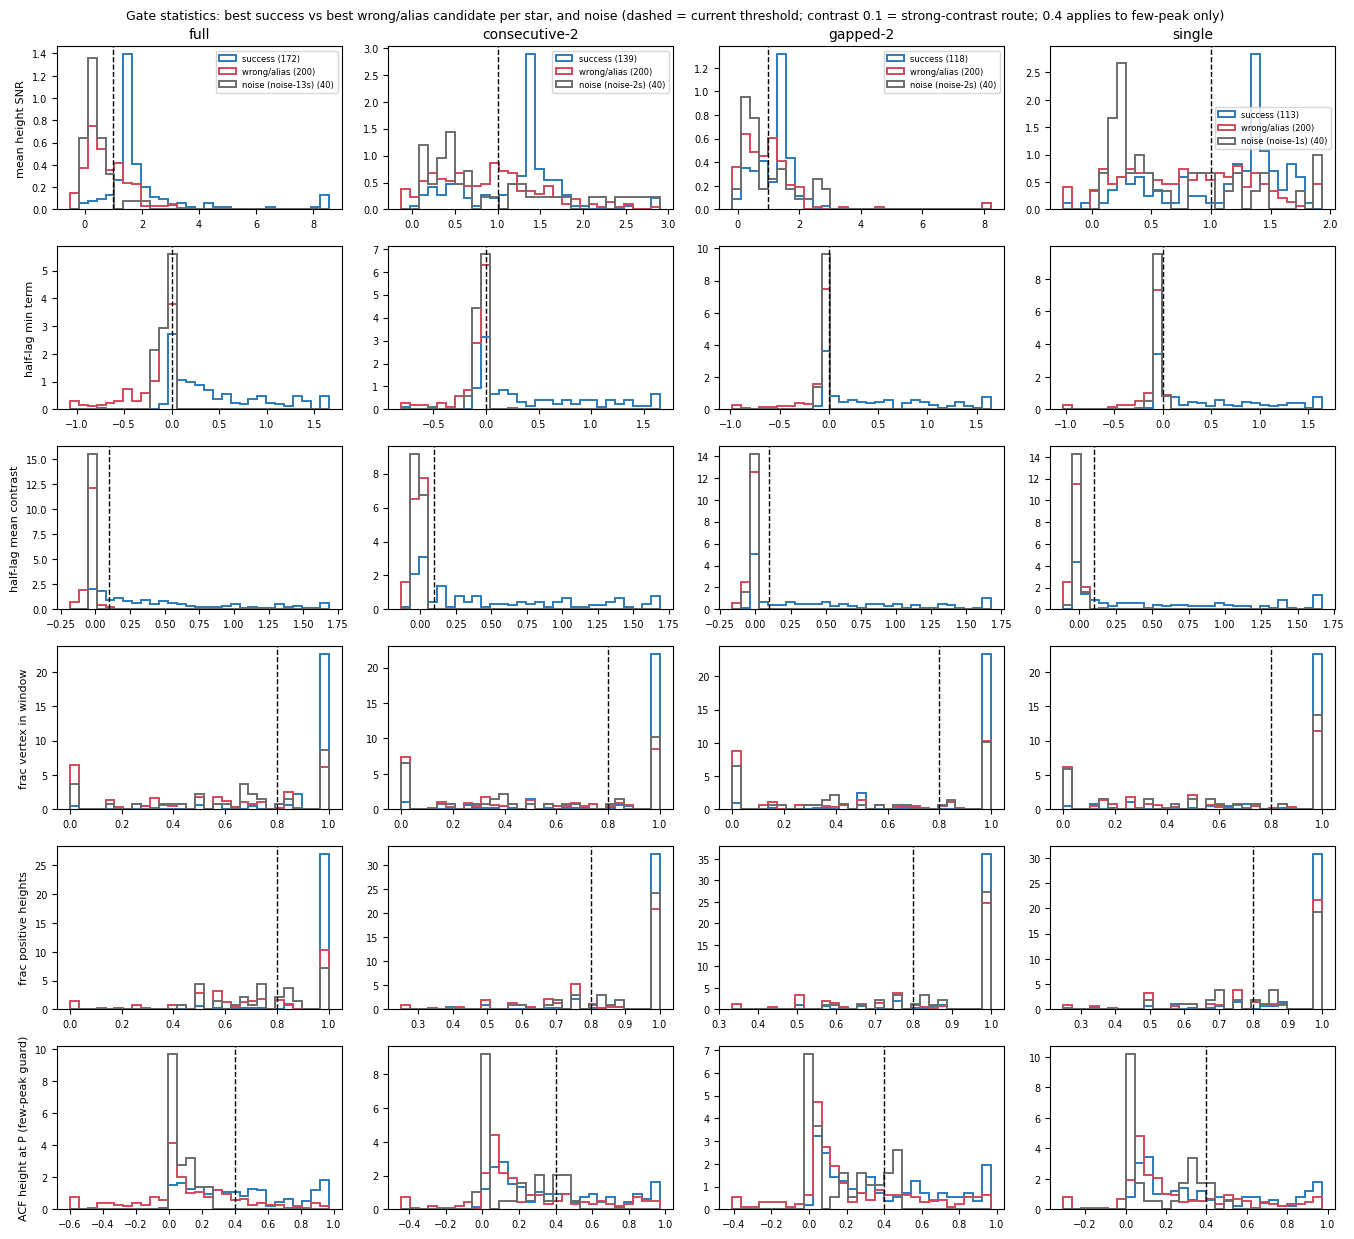

In [14]:
syn = cands[cands.dataset.isin(figs.COV_ORDER + ["noise-1s", "noise-2s", "noise-13s"])]
fig = figs.fig_stat_distributions(stars, syn, out="figures/fig_stat_distributions_synth.png")

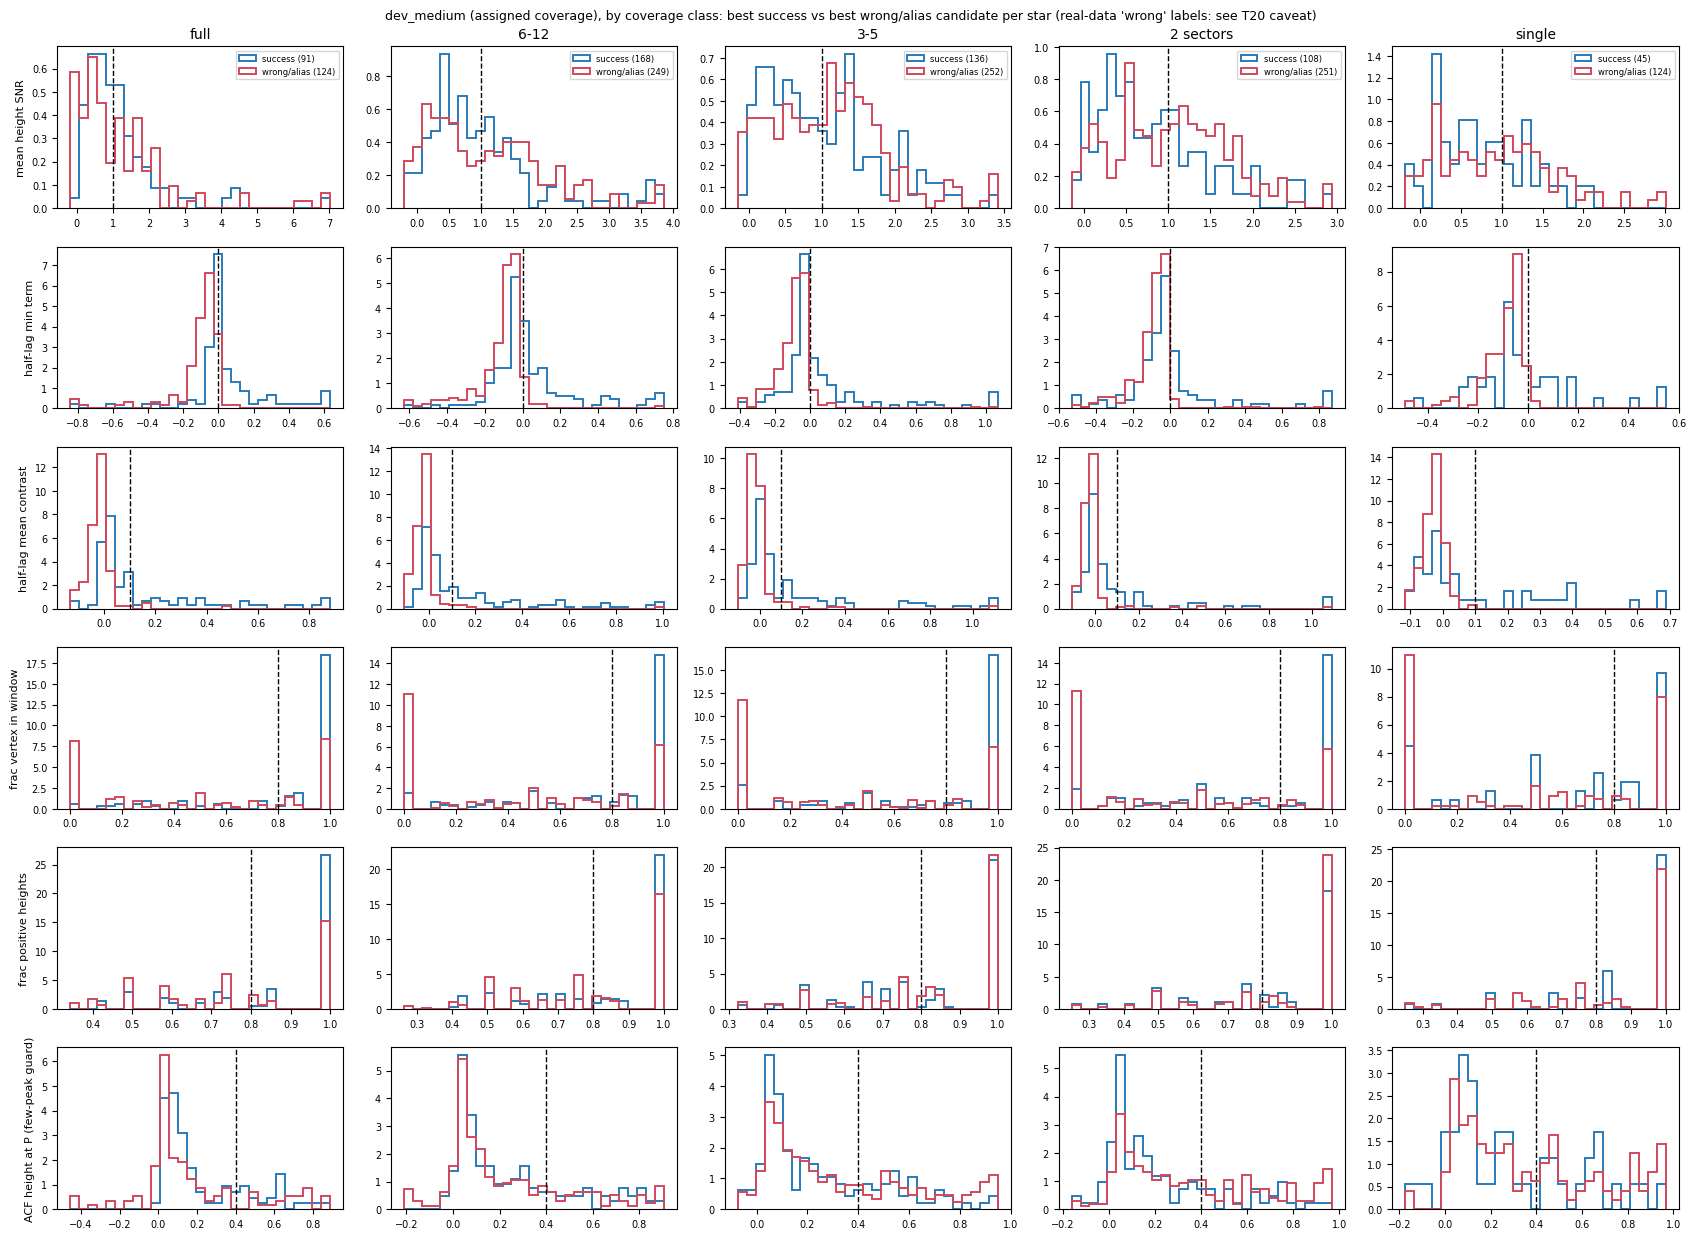

In [15]:
dm = cands[cands.dataset.eq("dev_medium")].merge(stars[["dataset", "star_id", "coverage_class"]],
                                                   on=["dataset", "star_id"])
dm["dataset"] = dm.coverage_class.map(lambda c: c if c in ("full", "single") else
                                          ("2 sectors" if c.endswith("-2") else ("3-5" if "3-5" in c else "6-12")))
fig = figs.fig_stat_distributions(stars, dm, datasets=["full", "6-12", "3-5", "2 sectors", "single"], noise_map=None,
                                  out="figures/fig_stat_distributions_dev_medium.png",
                                  title="dev_medium (assigned coverage), by coverage class: best success vs best wrong/alias "
                                        "candidate per star (real-data 'wrong' labels: see T20 caveat)")

## 5. Does any gate statistic scale with coverage?

Left/middle: the same synthetic star's matched `correct` candidate, short coverage vs full year.
Right: ACF height at P for every fitted candidate on pb_scan noise (circled: few-peak candidates, the only ones
the 0.4 guard applies to) and synthetic few-peak success candidates; dotted = 0.25.

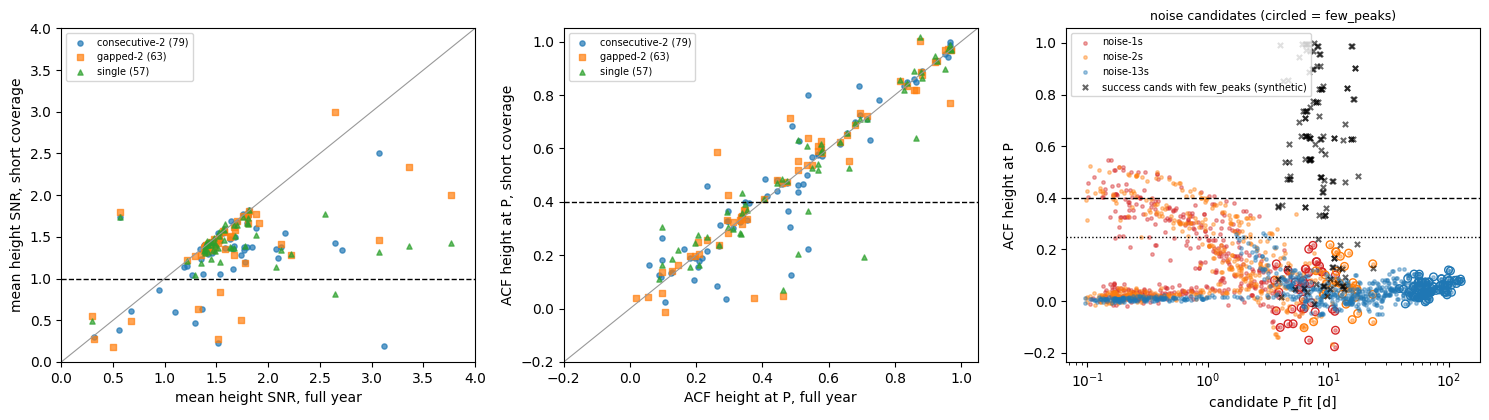

In [16]:
fig = figs.fig_scaling(stars, cands[cands.dataset.isin(figs.COV_ORDER + ["noise-1s", "noise-2s", "noise-13s"])],
                       out="figures/fig_scaling.png")

In [17]:
c = cands[cands.outcome.eq("correct") & cands.dataset.isin(figs.COV_ORDER)]
b = gl.best_per_star(c, c.P_fit.notna()); f = b[b.dataset == "full"].set_index("star_id")
out = {}
for ds in ["consecutive-2", "gapped-2", "single"]:
    j = b[b.dataset == ds].set_index("star_id").join(f, rsuffix="_f", how="inner")
    j = j[(j.P_fit / j.P_fit_f - 1).abs() < 0.05]
    out[ds] = {f"{col} ratio short/full ({q})": (j[col] / j[f"{col}_f"]).quantile(q)
               for col in ["mean_height_snr_value", "few_peaks_height_value", "half_lag_contrast"] for q in (0.25, 0.5)}
    out[ds]["n"] = len(j)
pd.DataFrame(out).round(3)

,consecutive-2,gapped-2,single
mean_height_snr_value ratio short/full (0.25),0.751,0.812,0.818
mean_height_snr_value ratio short/full (0.5),0.944,0.960,0.946
few_peaks_height_value ratio short/full (0.25),0.971,0.991,0.954
few_peaks_height_value ratio short/full (0.5),1.010,1.011,1.016
half_lag_contrast ratio short/full (0.25),0.971,0.972,0.933
half_lag_contrast ratio short/full (0.5),1.012,1.003,1.001
n,79.000,63.000,57.000


In [18]:
# when does the few-peak guard apply? share of success candidates that are few_peaks, by coverage and period bin
s = cands[cands.cls.eq("success") & cands.dataset.isin(figs.COV_ORDER)].merge(
    stars[["dataset", "star_id", "period_bin"]], on=["dataset", "star_id"])
pd.crosstab(s.dataset, s.period_bin, values=s.few_peaks.astype(bool), aggfunc="mean").round(2)[
    [b for b in gl.BIN_ORDER if b in set(s.period_bin)]]

period_bin,<1d,1-3d,3-10d,10-30d
dataset,,,,
consecutive-2,0.0,0.00,0.24,0.94
full,0.0,0.00,0.00,0.00
gapped-2,0.0,0.03,0.63,1.00
single,0.0,0.00,0.57,1.00


## 6. Examples

Blue = comb of the best success candidate, grey = lowest-redchi candidate; solid verticals at kP, dotted at
(k-1/2)P. The box lists the best success candidate's gate values.

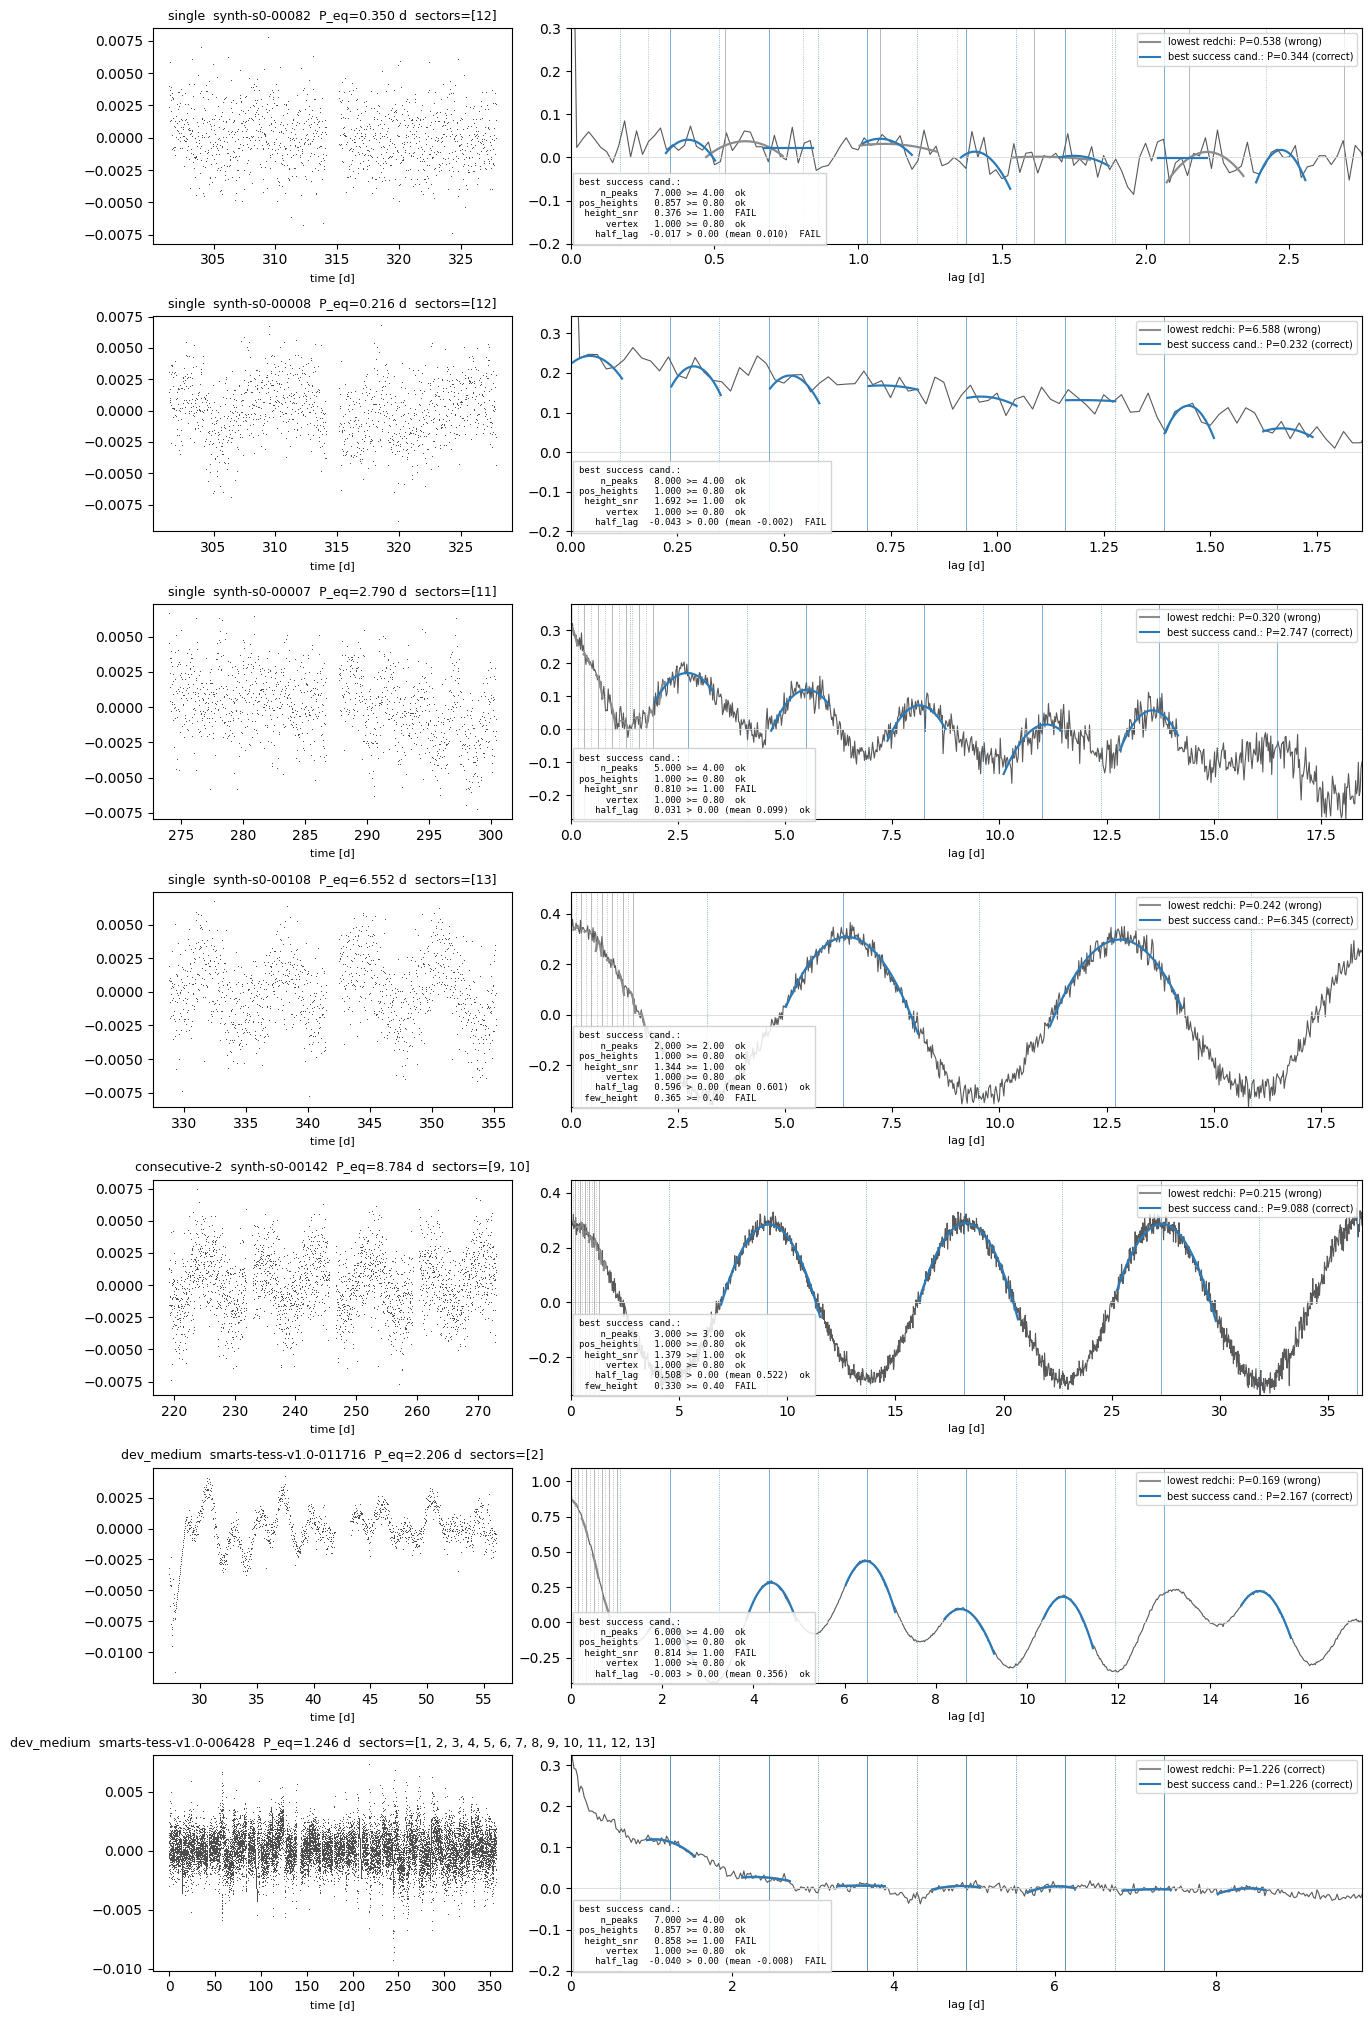

In [19]:
recs, arr = figs.load_examples()
fig = figs.fig_examples(recs, arr, out="figures/fig_examples.png")

## 7. Offline trade-offs of alternative gate rules

Replay: the selected candidate is the lowest-redchi candidate passing the rule (the pipeline's factor-of-2 alias
guard is not replayed; check below that the current-rule replay reproduces the real outcomes). Counts are deltas vs
the current rule; `d_noise` = extra pb_scan noise light curves that would get an answer (out of 40 per set).
Rules: `rules.py`. **Tuning sets** (seed 0, pb_scan noise offset 0); the PROPOSED2 rule was refined on these.

In [20]:
gl.replay_agreement(stars, cands)

,n,agree
dataset,,
consecutive-2,200,1.000
dev_medium,1000,0.998
full,200,1.000
gapped-2,200,1.000
noise-13s,40,1.000
noise-1s,40,1.000
noise-2s,40,1.000
s1-gapped-2,200,0.995
s1-single,200,0.995


In [21]:
TUNE = figs.COV_ORDER + ["noise-13s", "noise-2s", "noise-1s"]
t = gl.tradeoff(stars[stars.dataset.isin(TUNE)], cands[cands.dataset.isin(TUNE)], rules.RULES)
def show(t, ds_order):
    p = t.pivot_table(index="rule", columns="dataset", values=["d_success", "d_wrong", "d_alias", "d_noise"],
                      aggfunc="sum", sort=False)
    keep = [(m, d) for m in ["d_success", "d_wrong", "d_alias"] for d in ds_order if not d.startswith(("noise", "v-noise"))]
    keep += [("d_noise", d) for d in ds_order if d.startswith(("noise", "v-noise"))]
    return p[[k for k in keep if k in p.columns]]
trade_tune = show(t, TUNE)
trade_tune.to_csv("data/table_tradeoff_tuning.csv")
trade_tune

cls                                                d_success                               d_wrong                               d_alias                                 d_noise                  
dataset                                                 full consecutive-2 gapped-2 single    full consecutive-2 gapped-2 single    full consecutive-2 gapped-2 single noise-13s noise-2s noise-1s
rule                                                                                                                                                                                              
current                                                    0             0        0      0       0             0        0      0       0             0        0      0         0        0        0
option D (fallback contrast>0)                             4             0        0      1       3            32       35     39       4             1        7      3         0        0        0
few height >= 0.25                                         0             1        1      2       0             0        0      0       0             0        0      1         0        0        0
few height >= 0.25 (short only)                            0             1        1      2       0             0        0      0       0             0        0      1         0        0        0
few: height>=0.4 or contrast>=0.1                          0             5        1      2       0            -1        0      0       0             1        0      1         0        1        1
snr>=0.5 if contrast>=0.1                                  0             0        2      2       0             0        0      0       0             0       -1      1         1        0        0
vertex>=0.5 if contrast>=0.1                              -1             0        2      1       0             0        1      0       1             0        0      0         0        0        0
n_peaks-1 if contrast>=0.1                                 0             0        0      0       0             0        0      0       0             0        0      0         0        0        0
override: all terms>0 & contrast>=0.1                     -2             7        4      3       1            -1        3      4       1             3        0      1         1        4        5
override: all terms>0 & contrast>=0.2                     -2             2        2      2       1             0        2      1       1             2        0      1         0        2        2
PROPOSED (4 contrast-conditional relaxations)             -1             6        6      5       0            -1        1      3       1             1       -1      1         1        3        3
PROPOSED (short only)                                      0             6        6      5       0            -1        1      3       0             1       -1      1         0        3        3
snr>=0.5 if contrast>=0.1 & >=4 teeth                      0             0        2      2       0             0        0      0       0             0       -1      1         1        0        0
vertex>=0.5 if contrast>=0.1 & >=4 teeth                  -1             0        1      1       0             0        0      0       1             0        0      0         0        0        0
PROPOSED2 (few>=0.25; snr/vertex if contrast & ...        -1             1        4      5       0             0        0      0       1             0       -1      1         1        0        0
PROPOSED2 (short only)                                     0             1        4      5       0             0        0      0       0             0       -1      1         0        0        0
snr>=0.5 everywhere (no contrast cond.)                    1             2        3      3       8             2        3      6       1             0        0      2         6        0        0
half-lag: contrast>=0.0 (min term ignored)                 0             0       -1      1       7  

**Held-out validation** (synthetic seed 1, pb_scan noise seed offset 1500; nothing was tuned on these).

In [22]:
VAL = ["s1-single", "s1-gapped-2", "v-noise-13s", "v-noise-2s", "v-noise-1s"]
tv = gl.tradeoff(stars[stars.dataset.isin(VAL)], cands[cands.dataset.isin(VAL)], rules.RULES)
trade_valid = show(tv, VAL)
trade_valid.to_csv("data/table_tradeoff_validation.csv")
trade_valid

cls                                                d_success               d_wrong               d_alias                 d_noise                      
dataset                                            s1-single s1-gapped-2 s1-single s1-gapped-2 s1-single s1-gapped-2 v-noise-13s v-noise-2s v-noise-1s
rule                                                                                                                                                  
current                                                    0           0         0           0         0           0           0          0          0
option D (fallback contrast>0)                             1           4        27          28         2           4           1          0          1
few height >= 0.25                                         5           6         0           0         0           0           0          0          0
few height >= 0.25 (short only)                            5           6         0           0         0           0           0          0          0
few: height>=0.4 or contrast>=0.1                          6           9         1           0         0           0           0          3          0
snr>=0.5 if contrast>=0.1                                  1           1         0           0         0           0           0          0          0
vertex>=0.5 if contrast>=0.1                               0           0         0           0         0           0           0          0          0
n_peaks-1 if contrast>=0.1                                 0           0         0           0         0           0           0          0          0
override: all terms>0 & contrast>=0.1                      6          11         2           2         0           0           2          7          3
override: all terms>0 & contrast>=0.2                      6           7         2           2         0           0           0          2          0
PROPOSED (4 contrast-conditional relaxations)              7          10         1           0         0           0           2          6          1
PROPOSED (short only)                                      7          10         1           0         0           0           0          6          1
snr>=0.5 if contrast>=0.1 & >=4 teeth                      1           1         0           0         0           0           0          0          0
vertex>=0.5 if contrast>=0.1 & >=4 teeth                   0           0         0           0         0           0           0          0          0
PROPOSED2 (few>=0.25; snr/vertex if contrast & ...         6           7         0           0         0           0           1          0          0
PROPOSED2 (short only)                                     6           7         0           0         0           0           0          0          0
snr>=0.5 everywhere (no contrast cond.)                    2           2         2           2         1           0          10          1          0
half-lag: contrast>=0.0 (min term ignored)                 0           3        27          29         3           4           1          0          1

In [23]:
base_valid = tv[tv.rule == "current"].set_index("dataset")[["success", "alias", "wrong", "noise", "none"]]
base_valid

cls,success,alias,wrong,noise,none
dataset,,,,,
s1-gapped-2,71,1,0,0,128
s1-single,63,1,2,0,134
v-noise-13s,0,0,0,0,40
v-noise-1s,0,0,0,1,39
v-noise-2s,0,0,0,0,40


## 8. dev_medium (assigned coverage)
Real SMARTS light curves. Caveat (T20): some SMARTS noise galaxies may carry real periodic signals, so real-data
`wrong` labels may be partly unreliable; gate-firing counts are still valid.

In [24]:
d = stars[stars.dataset.eq("dev_medium")].copy()
d["cls"] = np.where(d.final_outcome.eq("none"), "none", gl.cand_class(d.final_outcome))
pd.crosstab(d.coverage_class, d.cls, margins=True)

cls,alias,none,success,wrong,All
coverage_class,,,,,
consecutive-2,1,104,10,10,125
consecutive-3-5,1,100,20,6,127
consecutive-6-12,0,90,30,5,125
full,4,81,33,6,124
gapped-2,0,111,10,5,126
gapped-3-5,1,99,20,5,125
gapped-6-12,2,93,17,12,124
single,0,111,8,5,124
All,9,789,148,54,1000


In [25]:
b = figs.rescue_candidates(stars, cands, "strict")
b = b[b.dataset.eq("dev_medium")]
gt = figs.gate_table(b, by=("coverage_class",))
gt.to_csv("data/table_gates_strict_dev_medium_by_class.csv")
gt

any                                                      sole                                                  
                 n_stars n_peaks pos_heights height_snr vertex half_lag few_height n_peaks pos_heights height_snr vertex half_lag few_height
coverage_class                                                                                                                              
consecutive-2         37       0          19         29     19       31          5       0           0          2      0        0          0
consecutive-3-5       45       0          22         32     22       35          6       0           1          2      2        3          0
consecutive-6-12      51       1          22         38     26       37         14       0           0          3      0        3          3
full                  43       0          23         39     12       33          3       0           0          4      1        0          0
gapped-2              34       1          17         30     20       25          5       0           0          1      0        0          0
gapped-3-5            31       0          21         25     16       25          3       0           0          2      0        0          0
gapped-6-12           46       1          20         40     21       31         11       0           0          5      1        1          2
single                25       0           6         20     19       20          7       0           0          1      1        0          0

In [26]:
b["structured"] = pd.cut(b.half_lag_contrast, [-np.inf, 0.02, 0.1, np.inf],
                         labels=["noise-like (<0.02)", "weak (0.02-0.1)", "structured (>=0.1)"])
pd.crosstab(b.coverage_class, b.structured, margins=True)

structured,noise-like (<0.02),weak (0.02-0.1),structured (>=0.1),All
coverage_class,,,,
consecutive-2,29,5,3,37
consecutive-3-5,33,5,7,45
consecutive-6-12,33,12,6,51
full,27,15,1,43
gapped-2,21,9,4,34
gapped-3-5,19,9,3,31
gapped-6-12,22,12,12,46
single,18,4,3,25
All,202,71,39,312


In [27]:
dmv = stars[stars.dataset.eq("dev_medium")]
td = gl.tradeoff(dmv, cands[cands.dataset.eq("dev_medium")], rules.RULES)
trade_dm = td.pivot_table(index="rule", values=["d_success", "d_wrong", "d_alias"], aggfunc="sum", sort=False)
trade_dm.to_csv("data/table_tradeoff_dev_medium.csv")
trade_dm

cls,d_success,d_wrong,d_alias
rule,,,
current,0,0,0
option D (fallback contrast>0),10,36,2
few height >= 0.25,5,6,1
few height >= 0.25 (short only),1,4,0
few: height>=0.4 or contrast>=0.1,12,18,4
snr>=0.5 if contrast>=0.1,19,36,4
vertex>=0.5 if contrast>=0.1,6,3,0
n_peaks-1 if contrast>=0.1,0,1,1
override: all terms>0 & contrast>=0.1,53,102,19


In [28]:
# dev_medium by coverage class for the proposed rule
r = gl.replay(cands[cands.dataset.eq("dev_medium")], rules.PROPOSED2, stars=dmv)
cur = gl.replay(cands[cands.dataset.eq("dev_medium")], {}, stars=dmv)
r = r.merge(dmv[["dataset", "star_id", "coverage_class"]], on=["dataset", "star_id"])
cur = cur.merge(dmv[["dataset", "star_id", "coverage_class"]], on=["dataset", "star_id"])
(gl.outcome_counts(r, by=("coverage_class",)) - gl.outcome_counts(cur, by=("coverage_class",))).drop(columns="noise")

cls,success,alias,wrong,none
coverage_class,,,,
consecutive-2,3,1,7,-11
consecutive-3-5,4,1,6,-11
consecutive-6-12,4,0,3,-7
full,3,1,8,-12
gapped-2,2,1,4,-7
gapped-3-5,1,-1,6,-6
gapped-6-12,7,1,4,-12
single,5,1,6,-12
